In [1]:
import matplotlib.pyplot as plt
import numpy as np
import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [34]:
import os

In [35]:
plt.rcParams['font.size'] = 14

In [36]:
import pylab_util as PU

In [37]:
wn = 5*2*pi
z = 0.1

In [38]:
G = TF(wn**2,[1,2*z*wn,wn**2])
G

TransferFunction(
array([986.96044011]),
array([  1.        ,   6.28318531, 986.96044011]),
outputs=1, inputs=1)

In [39]:
f = np.logspace(-1,2,1000)
w = 2*pi*f
s = 1j*w

In [40]:
Gjw = G(s)

In [41]:
import bode_utils

In [42]:
from krauss_misc import rwkos

In [43]:
rwkos.make_dir('figs')

cmd=epstopdf figs/MSD_bode_intro.eps
pdfcrop figs/MSD_bode_intro.pdf figs/MSD_bode_intro.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/MSD_bode_intro.pdf'.


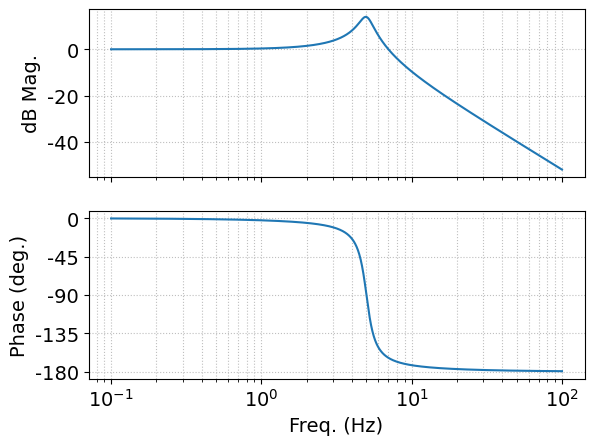

In [44]:
bode_utils.bode_plot_from_complex(f,Gjw)
PU.mysave("figs/MSD_bode_intro.eps")

In [45]:
f_list = [0.7, 5, 30]

In [46]:
bode_utils.bode_plot??

Signature:
bode_utils.bode_plot(
    freq,
    dB_mag,
    phase,
    fig=None,
    fignum=1,
    clear=True,
    xlim=None,
    label=None,
    fmt='-',
    grid=True,
    figsize=None,
    unwrap=False,
    **kwargs,
)
Source:   
def bode_plot(freq, dB_mag, phase, fig=None, fignum=1, clear=True, xlim=None, \
              label=None, fmt='-', grid=True, figsize=None, unwrap=False, \
              **kwargs):
    """This function plots a very nice Bode plot.  freq is a vector in
    Hz.  dB_mag and phase are vectors with the same length as freq."""
    fig = _get_fig(fig, fignum, figsize=figsize)
    if clear:
        fig.clf()

    if len(fig.axes) > 1:
        ax = fig.axes[0]
    else:
        ax = fig.add_subplot(211)

    if unwrap:
        phase = unwrap_deg(phase)
        
    ax.semilogx(freq, dB_mag, fmt, label=label, **kwargs)
    ax.set_ylabel('dB Mag.')

    set_log_ticks(ax,nullx=True)
    set_db_ticks(ax, dB_mag)

    if grid:
        mygrid(ax)
        #ax.grid(1)

    i

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


cmd=epstopdf figs/fixed_sine_ss_0_7_Hz.eps
pdfcrop figs/fixed_sine_ss_0_7_Hz.pdf figs/fixed_sine_ss_0_7_Hz.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


==> 1 page written on `figs/fixed_sine_ss_0_7_Hz.pdf'.
cmd=epstopdf figs/fixed_sine_ss_5_Hz.eps
pdfcrop figs/fixed_sine_ss_5_Hz.pdf figs/fixed_sine_ss_5_Hz.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/fixed_sine_ss_5_Hz.pdf'.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


cmd=epstopdf figs/fixed_sine_ss_30_Hz.eps
pdfcrop figs/fixed_sine_ss_30_Hz.pdf figs/fixed_sine_ss_30_Hz.pdf
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `figs/fixed_sine_ss_30_Hz.pdf'.


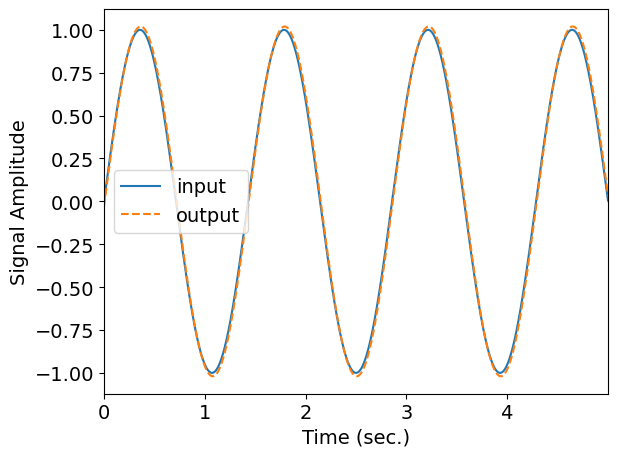

<Figure size 640x480 with 0 Axes>

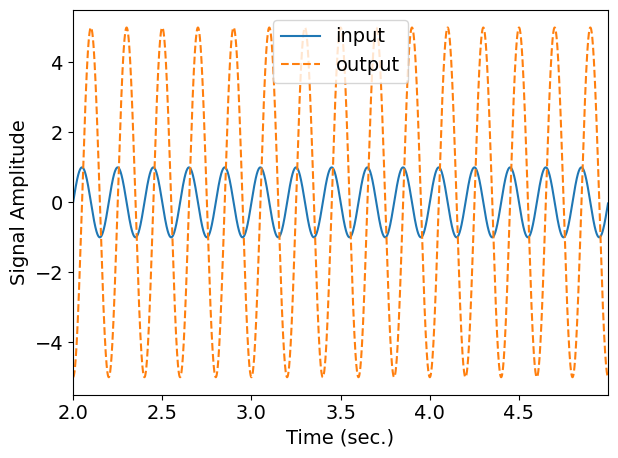

<Figure size 640x480 with 0 Axes>

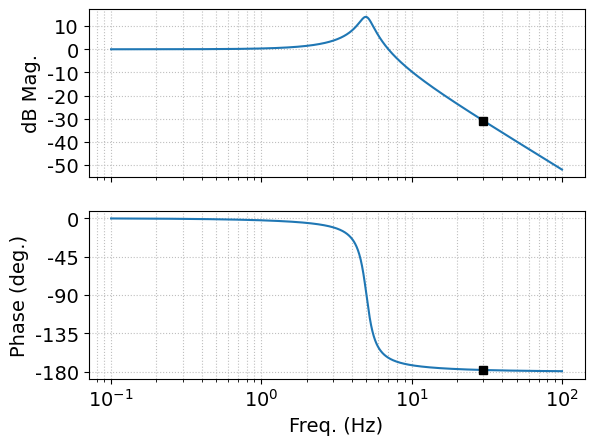

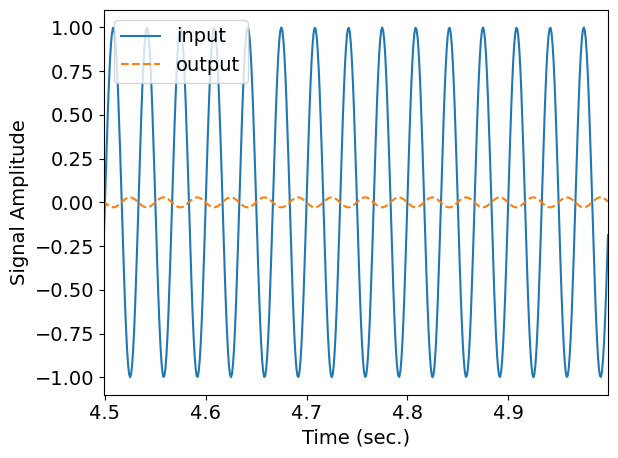

In [53]:
fmt_strs = ['ko','k^','ks']

t = np.arange(0,5,0.001)

t_limits = [5, 3, 0.5]
t_max = t.max()

for f_i, fmt, tl in zip(f_list, fmt_strs, t_limits):
    plt.figure()
    bode_utils.bode_plot_from_complex(f,Gjw,clear=True)
    w_i = 2*pi*f_i
    s_i = 1j*w_i
    Gjw_i = G(s_i)
    M_i = np.abs(Gjw_i)
    phase_i = np.angle(Gjw_i, 1)
    phi_i = np.angle(Gjw_i)
    dB_i = 20*np.log10(M_i)
    fig = plt.gcf()
    bode_utils.bode_plot(np.array([f_i]),np.array([dB_i]),np.array([phase_i]),\
                         clear=False, fmt=fmt, fig=fig)
    fn = "bode_vs_fixed_%0.4g_Hz.eps" % f_i
    fn = rwkos.clean_filename(fn)
    #PU.mysave(os.path.join("figs",fn))

    u = np.sin(2*pi*f_i*t)
    y_ss = M_i*np.sin(2*pi*f_i*t+phi_i)
    plt.figure()
    plt.plot(t,u,t,y_ss,'--')
    plt.xlabel('Time (sec.)')
    plt.ylabel('Signal Amplitude')
    plt.legend(['input','output'])
    plt.xlim([t_max-tl, t_max])

    fn_fixed = "fixed_sine_ss_%0.4g_Hz.eps" % f_i
    fn_fixed = rwkos.clean_filename(fn_fixed)
    plt.tight_layout()
    PU.mysave(os.path.join("figs",fn_fixed))
    
    